# Step 7: Model 4 - PyTorch with TabNet (attention-based network for tables).

In [1]:
# Run from the project root so data/, figures/ and results/ paths work
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%matplotlib inline

In [2]:
import time

import matplotlib.pyplot as plt
import pandas as pd
from pytorch_tabnet.tab_model import TabNetRegressor

from config import RANDOM_STATE
from utils import load_data, evaluate, save_results, scale, validation_split

X_train, X_test, y_train, y_test, X_latest = load_data()
X_train_s, X_test_s, X_latest_s = scale(X_train, X_test, X_latest)
X_tr, X_val, y_tr, y_val = validation_split(X_train_s, y_train)

model = TabNetRegressor(
    n_d=8, n_a=8,          # width of the decision / attention layers
    n_steps=3,             # number of sequential "attention" steps
    gamma=1.3,
    seed=RANDOM_STATE,
    verbose=10,
)

start = time.time()
model.fit(
    X_tr.values, y_tr.values.reshape(-1, 1),          # TabNet needs a 2-D target
    eval_set=[(X_val.values, y_val.values.reshape(-1, 1))],
    eval_name=["valid"], eval_metric=["rmse"],
    max_epochs=200, patience=20,
    batch_size=128, virtual_batch_size=64,
)
train_seconds = time.time() - start

y_pred = model.predict(X_test_s.values).ravel()
metrics = evaluate(y_test, y_pred, y_train)
expected = model.predict(X_latest_s.values).ravel()
save_results("tabnet", metrics, y_test, y_pred, expected, train_seconds)

Train: 2010-03-31 -> 2023-06-23 (667 rows)
Test : 2023-06-30 -> 2026-10-21 (167 rows)


C:\Projects\stock-return-prediction\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


C:\Projects\stock-return-prediction\.venv\Lib\site-packages\torch\utils\data\_utils\collate.py:288: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  return collate([torch.as_tensor(b) for b in batch], collate_fn_map=collate_fn_map)


epoch 0  | loss: 0.51117 | valid_rmse: 0.96223 |  0:00:00s


epoch 10 | loss: 0.0055  | valid_rmse: 0.07164 |  0:00:00s


epoch 20 | loss: 0.00268 | valid_rmse: 0.04954 |  0:00:01s


... (8 outputs left out)

epoch 110| loss: 0.00145 | valid_rmse: 0.04067 |  0:00:09s


epoch 120| loss: 0.00158 | valid_rmse: 0.04072 |  0:00:10s

Early stopping occurred at epoch 121 with best_epoch = 101 and best_valid_rmse = 0.04001
  model                            tabnet
  RMSE                             0.0378
  MAE                              0.0267
  R2                               -0.0227
  Directional_Accuracy             0.5150
  Baseline_RMSE                    0.0374
  Baseline_MAE                     0.0256
  Baseline_Directional_Accuracy    0.5629
  train_seconds                    12.2500
  expected_weekly_log_return       0.0690
  expected_weekly_return_pct       7.1401
  expected_annualised_return_pct   3510.0658


C:\Projects\stock-return-prediction\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


{'model': 'tabnet',
 'RMSE': 0.03777728226577918,
 'MAE': 0.026663877005627584,
 'R2': -0.02271566855330942,
 'Directional_Accuracy': 0.5149700598802395,
 'Baseline_RMSE': 0.037376898528065326,
 'Baseline_MAE': 0.02558297501644675,
 'Baseline_Directional_Accuracy': 0.562874251497006,
 'train_seconds': 12.25,
 'expected_weekly_log_return': 0.06896752119064331,
 'expected_weekly_return_pct': np.float64(7.140141074107986),
 'expected_annualised_return_pct': np.float64(3510.065834634664)}

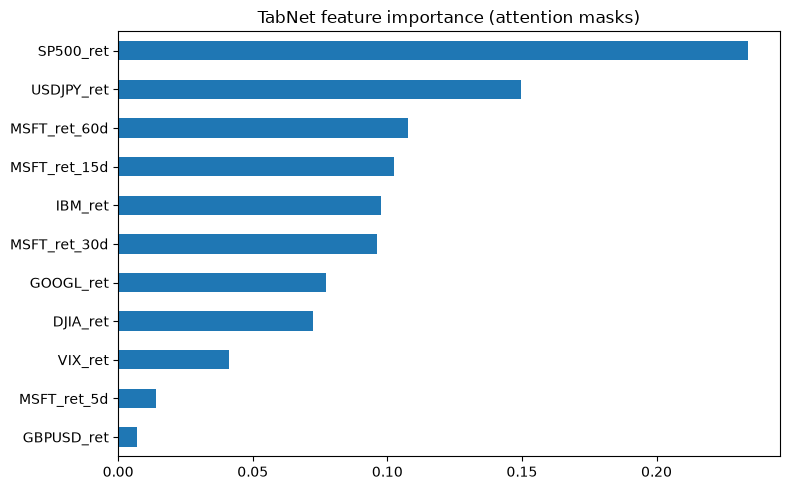

In [3]:
# TabNet's built-in feature importance (from its attention masks) - its transparency advantage
imp = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
imp.plot.barh(figsize=(8, 5), title="TabNet feature importance (attention masks)")
plt.tight_layout(); plt.savefig("figures/tabnet_importance.png", dpi=120); plt.show()